# Studying PBO in finite samples

Repeated controlled samples estimate the mean PBO and the uncertainty of that simulation mean:

$$
\overline\phi_M=\frac{1}{M}\sum_{m=1}^{M}\widehat\phi^{(m)},
\qquad
\widehat{\operatorname{SE}}(\overline\phi_M)=\frac{s_\phi}{\sqrt M}.
$$

Here, $M$ is the number of simulated samples, $\widehat\phi^{(m)}$ is the PBO in sample $m$, $\overline\phi_M$ is their mean, and $s_\phi$ is their sample standard deviation. Simulation is used because public history does not reveal repeated samples or the true presence of an edge.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from itertools import combinations
import hashlib
import math
import sys
import time
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset

from RiskLabAI.backtest.probability_of_backtest_overfitting import probability_of_backtest_overfitting
from RiskLabAI.backtest.validation import adaptive_probability_of_backtest_overfitting, bagged_probability_of_backtest_overfitting

DATA_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
DATA_DIR = ROOT / "data" / "public" / "fred"
DATA_PATH = ensure_dataset(ROOT, "fred_sp500")
EXPECTED_DATA_HASH = "2098B209EE3AFDB3B2C1E783AC90A2BB7DD3865FEB416D0FABEDBB4A7A542754"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
raw = pd.read_csv(DATA_PATH)
raw["observation_date"] = pd.to_datetime(raw["observation_date"])
prices = raw.set_index("observation_date")["SP500"].dropna().astype(float).sort_index()
log_returns = np.log(prices).diff()

fast_windows = [3, 5, 10, 20]
slow_windows = [30, 60, 120, 240]
performance_columns = {}
catalog_rows = []
for fast_window in fast_windows:
    for slow_window in slow_windows:
        fast_average = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow_average = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
        trend_position = np.sign(fast_average - slow_average).replace(0, np.nan).ffill().shift(1)
        for orientation, multiplier in [("Trend", 1.0), ("Reversal", -1.0)]:
            name = f"{orientation} {fast_window}/{slow_window}"
            performance_columns[name] = multiplier * trend_position * log_returns
            catalog_rows.append({"Trial": len(catalog_rows) + 1, "Rule": orientation, "Fast span": fast_window, "Slow span": slow_window, "Name": name})
performances = pd.DataFrame(performance_columns).dropna()
strategy_catalog = pd.DataFrame(catalog_rows)

FIGURES = ROOT / "outputs" / "figures" / "19_backtest_overfitting"
TABLES = ROOT / "outputs" / "tables" / "19_backtest_overfitting"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def score_vector(matrix):
    values = np.asarray(matrix, dtype=float)
    deviations = values.std(axis=0)
    means = values.mean(axis=0)
    return np.divide(means, deviations, out=np.zeros_like(means), where=deviations > 0)

def cscv_records(matrix, n_partitions, names=None):
    values = np.asarray(matrix, dtype=float)
    labels = list(names) if names is not None else [f"Trial {index + 1}" for index in range(values.shape[1])]
    groups = np.array_split(np.arange(values.shape[0]), n_partitions)
    all_groups = list(range(n_partitions))
    rows = []
    for combination_number, train_groups in enumerate(combinations(all_groups, n_partitions // 2), start=1):
        test_groups = tuple(group for group in all_groups if group not in train_groups)
        train_indices = np.concatenate([groups[group] for group in train_groups])
        test_indices = np.concatenate([groups[group] for group in test_groups])
        train_scores = score_vector(values[train_indices])
        test_scores = score_vector(values[test_indices])
        selected = int(np.argmax(train_scores))
        ranks = np.argsort(np.argsort(test_scores)) + 1
        selected_rank = int(ranks[selected])
        relative_rank = selected_rank / (values.shape[1] + 1)
        logit = float(np.log(relative_rank / (1.0 - relative_rank)))
        rows.append({"Combination": combination_number, "Training groups": ", ".join(str(group + 1) for group in train_groups), "Testing groups": ", ".join(str(group + 1) for group in test_groups), "Training observations": len(train_indices), "Testing observations": len(test_indices), "Selected trial": selected + 1, "Selected name": labels[selected], "In-sample score": train_scores[selected], "Out-of-sample score": test_scores[selected], "Out-of-sample rank": selected_rank, "Relative rank": relative_rank, "Logit": logit, "Overfit": int(logit <= 0.0)})
    return pd.DataFrame(rows)

def manual_pbo(matrix, n_partitions):
    records = cscv_records(matrix, n_partitions)
    return float(records["Overfit"].mean()), records["Logit"].to_numpy()
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Sensitivity

,Trials,Time groups,Logits,PBO,Mean logit,Logit spread
0,4,4,6,0.333333,0.625570,1.218642
1,4,6,20,0.350000,0.170681,1.076957
2,4,8,70,0.342857,0.253539,0.888399
3,4,10,252,0.246032,0.571815,0.847931
4,4,12,924,0.416667,0.184343,0.978215
5,8,4,6,0.333333,0.290495,1.706785
6,8,6,20,0.450000,0.036942,0.861709
7,8,8,70,0.428571,0.055259,1.045847
8,8,10,252,0.341270,0.335861,0.971387
9,8,12,924,0.476190,0.032687,1.027132


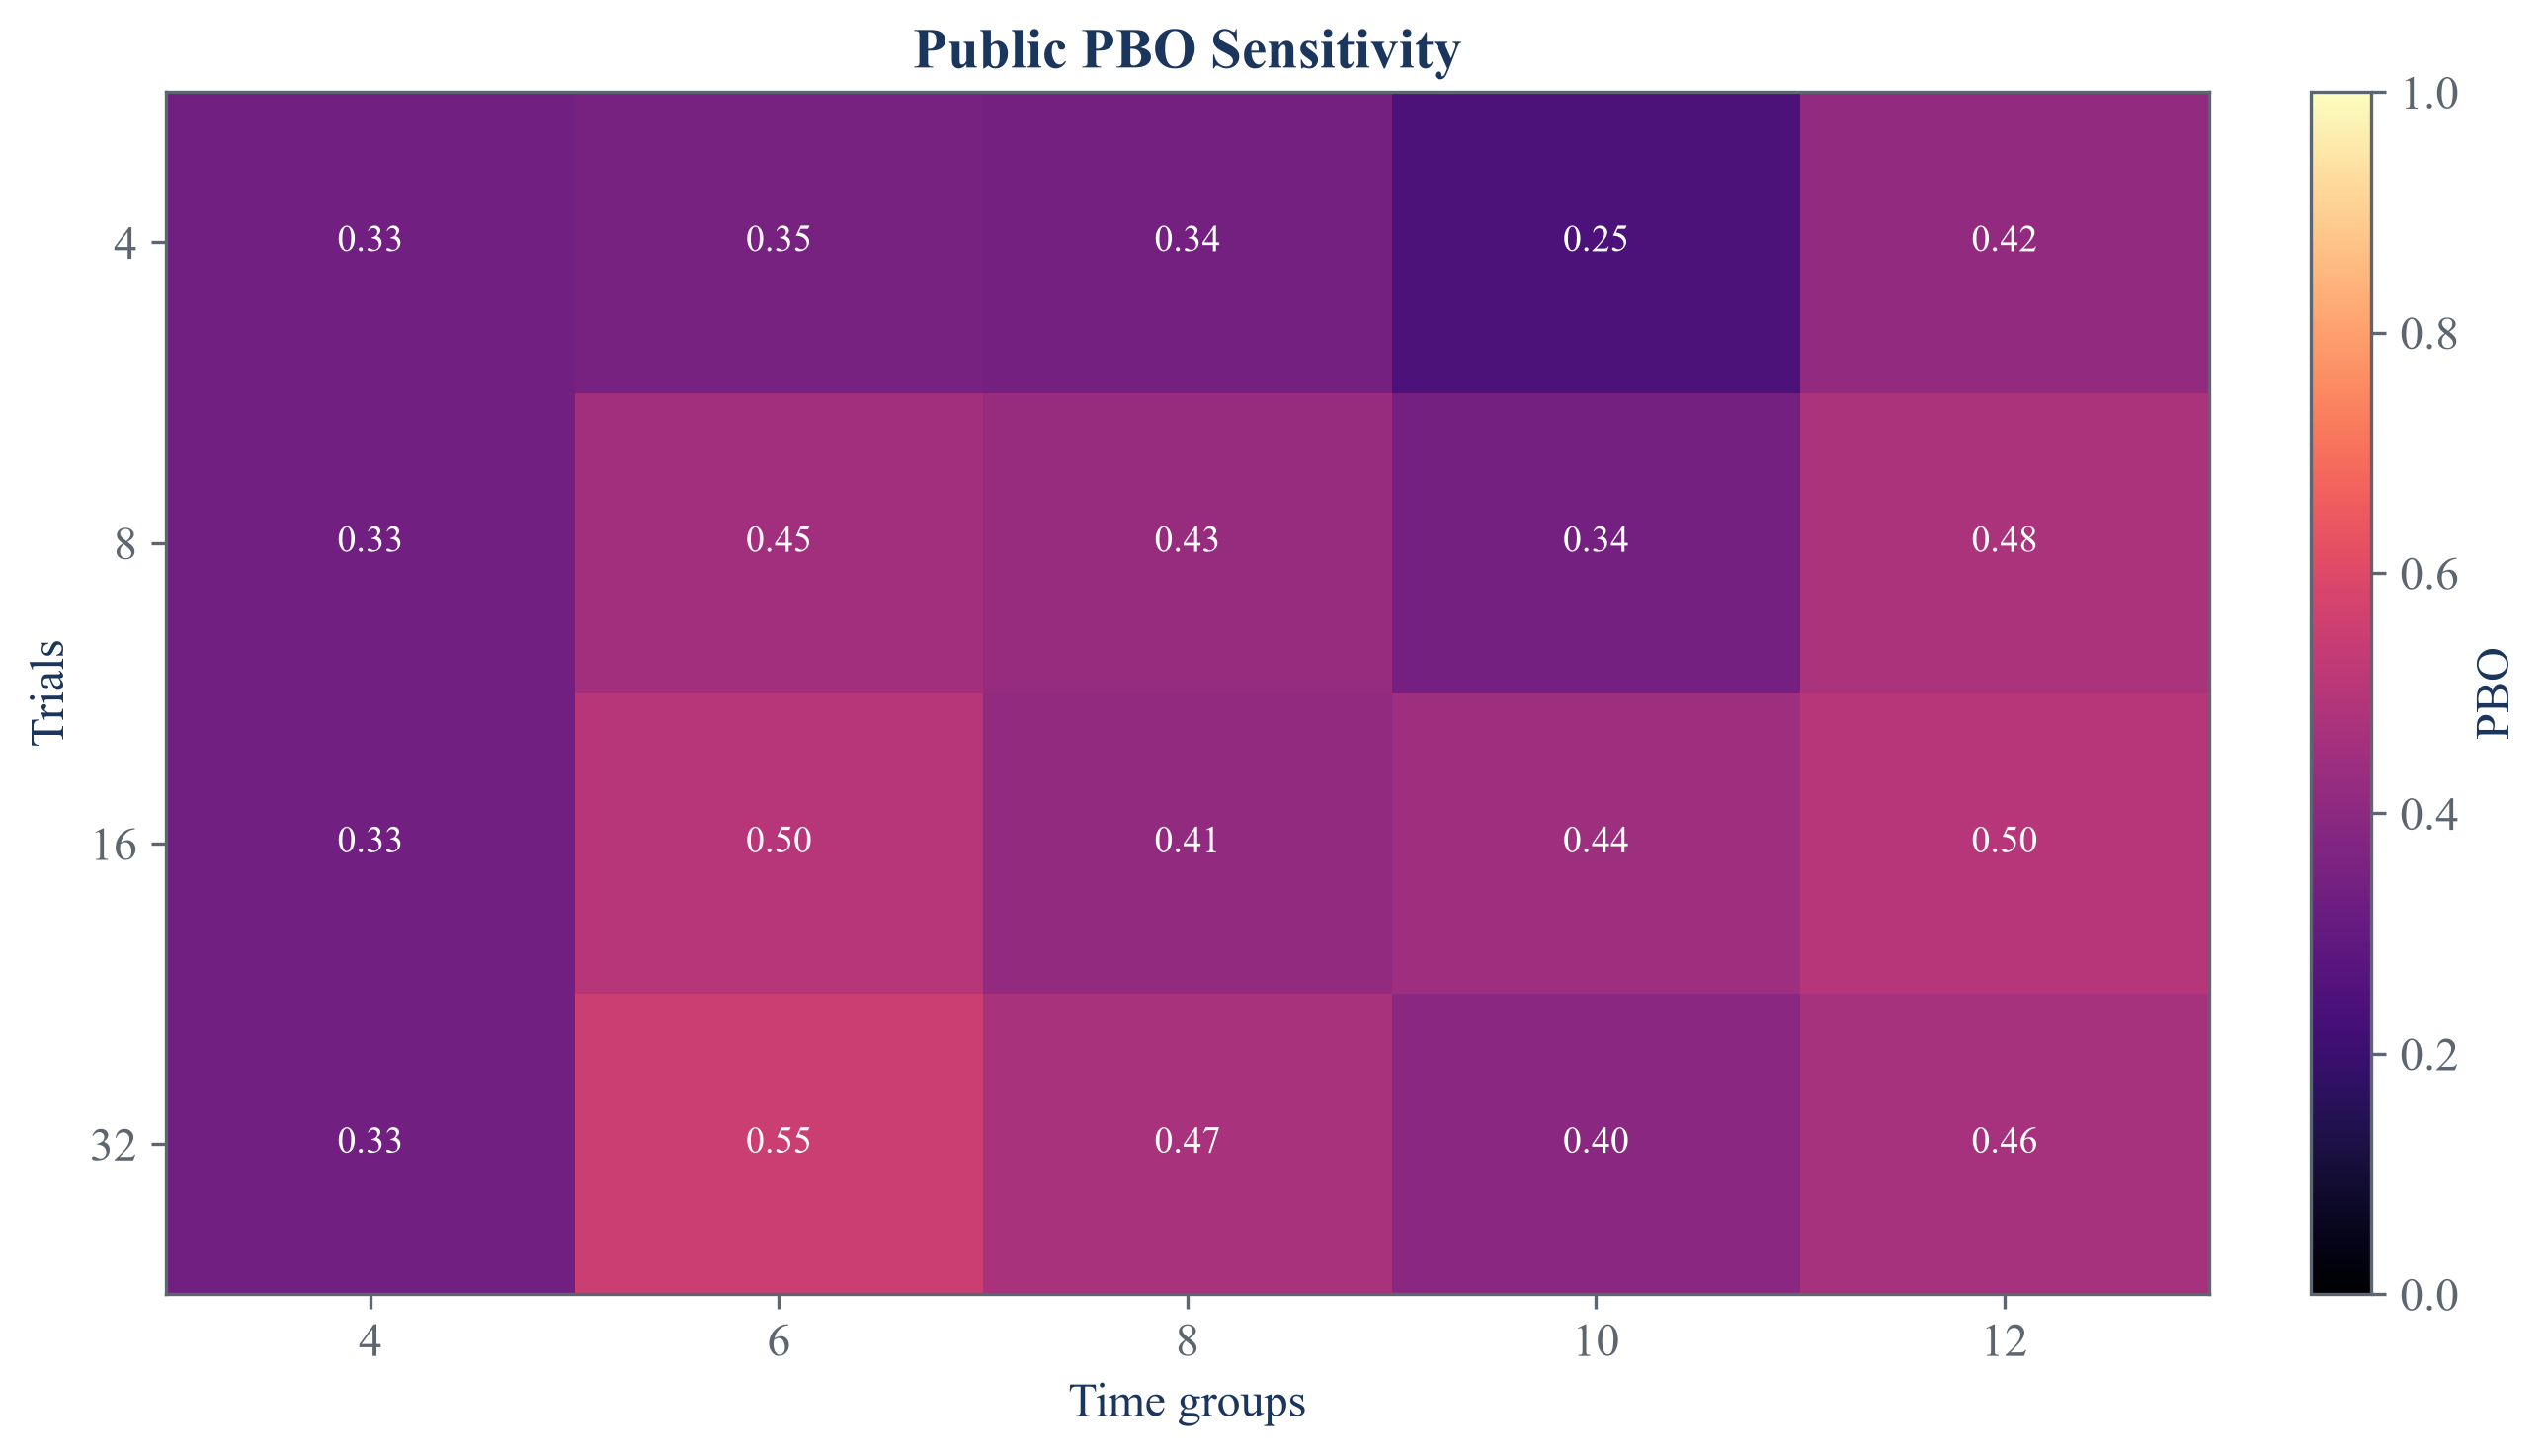

In [2]:
partition_choices = [4, 6, 8, 10, 12]
trial_choices = [4, 8, 16, 32]
sensitivity_rows = []
for trial_count in trial_choices:
    chosen = np.unique(np.rint(np.linspace(0, performances.shape[1] - 1, trial_count)).astype(int))
    matrix = performances.iloc[:, chosen].to_numpy()
    for partition_count in partition_choices:
        value, logits = manual_pbo(matrix, partition_count)
        sensitivity_rows.append({"Trials": len(chosen), "Time groups": partition_count, "Logits": len(logits), "PBO": value, "Mean logit": logits.mean(), "Logit spread": logits.std(ddof=1)})
public_sensitivity = pd.DataFrame(sensitivity_rows)
save_table(public_sensitivity, "public_sensitivity", "Public PBO sensitivity to the trial count and time-group count.", "tab:chapter17-public-sensitivity")
display(public_sensitivity)

heatmap = public_sensitivity.pivot(index="Trials", columns="Time groups", values="PBO")
figure, axis = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
image = axis.imshow(heatmap.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="magma")
axis.set_title("Public PBO Sensitivity")
axis.set_xlabel("Time groups")
axis.set_ylabel("Trials")
axis.set_xticks(np.arange(len(heatmap.columns)), heatmap.columns)
axis.set_yticks(np.arange(len(heatmap.index)), heatmap.index)
for row in range(heatmap.shape[0]):
    for column in range(heatmap.shape[1]):
        axis.text(column, row, f"{heatmap.iloc[row, column]:.2f}", ha="center", va="center", color="white", fontsize=9)
figure.colorbar(image, ax=axis, label="PBO")
figure.savefig(FIGURES / "public_pbo_sensitivity.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_pbo_sensitivity.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_pbo_sensitivity.png")))
plt.close(figure)

The number of logits grows quickly with the number of time groups:

$$
C_S=\binom{S}{S/2},
\qquad
C_{S+2}=C_S\frac{(S+2)(S+1)}{(S/2+1)^2}.
$$

Here, $S$ is an even number of time groups, $C_S$ is the resulting number of logits, and the second expression gives the exact growth when two groups are added.

## Controlled Experiments

Each simulated trial combines a common shock, its own shock, time-varying volatility, and a declared mean pattern:

$$
R_{t,n}=\sigma_t\left(\sqrt\rho\,Z_t+\sqrt{1-\rho}\,\varepsilon_{t,n}\right)+\mu_{t,n}.
$$

Here, $R_{t,n}$ is the return of trial $n$ at time $t$, $\sigma_t$ is a changing volatility scale, $\rho$ is the common-shock share, $Z_t$ is a shock shared by all trials, $\varepsilon_{t,n}$ is a trial-specific shock, and $\mu_{t,n}$ is the known mean pattern used to create no edge, one persistent edge, or a reversal.

,Condition,Known mean pattern,Trials,Time groups,Repetitions per sample size
0,No edge,Every trial has zero mean,16,8,40
1,Persistent edge,Trial 1 has mean 0.0015 throughout,16,8,40
2,Reversing edge,Trial 1 leads in the first 75 percent and tria...,16,8,40


,Condition,Observations,Mean PBO,PBO spread,Mean logit,Simulation standard error
0,No edge,120,0.527143,0.220052,-0.061888,0.034793
1,No edge,240,0.463214,0.237660,0.128369,0.037577
2,No edge,480,0.445000,0.203361,0.147467,0.032154
3,No edge,960,0.570000,0.192611,-0.171346,0.030454
4,Persistent edge,120,0.427143,0.206736,0.210155,0.032688
5,Persistent edge,240,0.352143,0.205129,0.614528,0.032434
6,Persistent edge,480,0.269286,0.225054,1.149260,0.035584
7,Persistent edge,960,0.129286,0.156490,1.869576,0.024743
8,Reversing edge,120,0.380000,0.180696,0.328329,0.028571
9,Reversing edge,240,0.452857,0.233312,0.122162,0.036890


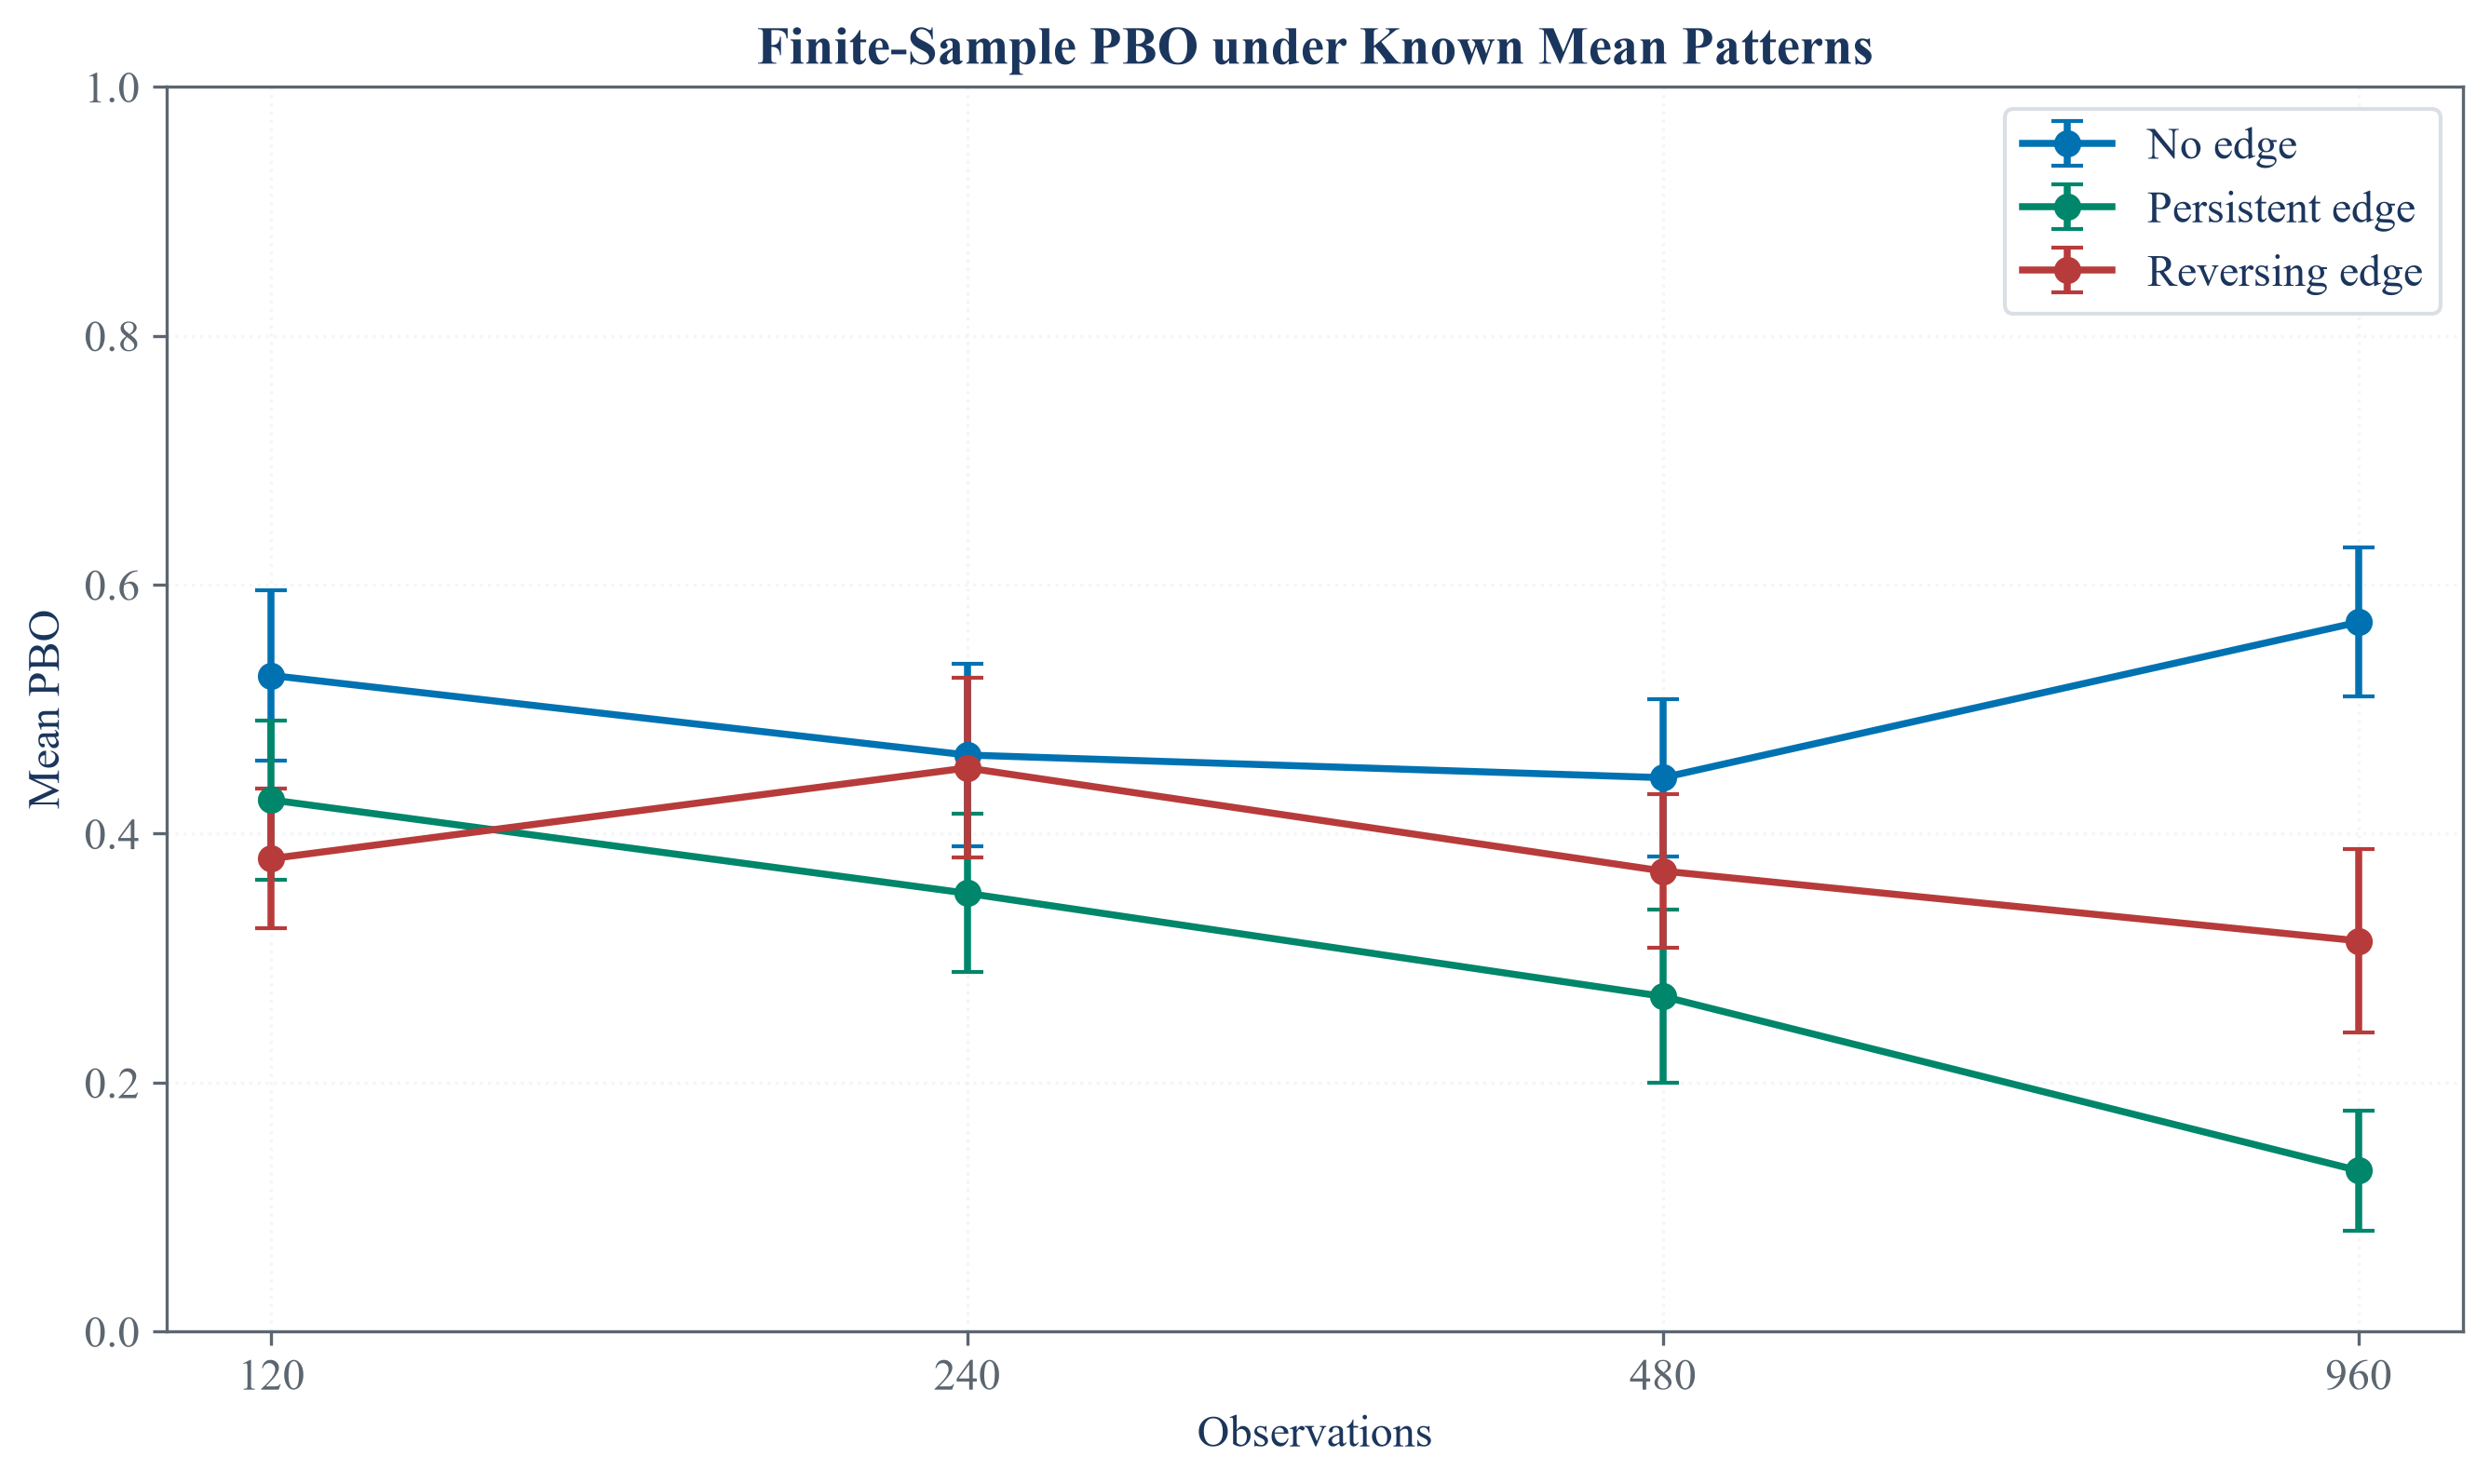

In [3]:
def simulate_trial_matrix(condition, n_observations, n_trials, seed):
    rng = np.random.default_rng(seed)
    log_scale = np.zeros(n_observations)
    volatility_shocks = rng.normal(0, 0.16, n_observations)
    for index in range(1, n_observations):
        log_scale[index] = 0.96 * log_scale[index - 1] + volatility_shocks[index]
    scales = 0.01 * np.exp(np.clip(log_scale, -1.0, 1.0))
    common = rng.standard_t(7, n_observations)
    individual = rng.standard_t(7, (n_observations, n_trials))
    values = scales[:, None] * (np.sqrt(0.30) * common[:, None] + np.sqrt(0.70) * individual)
    if condition == "Persistent edge":
        values[:, 0] += 0.0015
    if condition == "Reversing edge":
        boundary = int(0.75 * n_observations)
        values[:boundary, 0] += 0.0015
        values[boundary:, -1] += 0.0025
        values[boundary:] *= 1.6
    return values

simulation_design = pd.DataFrame({
    "Condition": ["No edge", "Persistent edge", "Reversing edge"],
    "Known mean pattern": ["Every trial has zero mean", "Trial 1 has mean 0.0015 throughout", "Trial 1 leads in the first 75 percent and trial 16 leads in the last 25 percent"],
    "Trials": [16, 16, 16],
    "Time groups": [8, 8, 8],
    "Repetitions per sample size": [40, 40, 40],
})
simulation_rows = []
sample_sizes = [120, 240, 480, 960]
for condition_number, condition in enumerate(simulation_design["Condition"]):
    for sample_size in sample_sizes:
        for repetition in range(40):
            matrix = simulate_trial_matrix(condition, sample_size, 16, 100000 * condition_number + 1000 * sample_size + repetition)
            value, logits = manual_pbo(matrix, 8)
            simulation_rows.append({"Condition": condition, "Observations": sample_size, "Repetition": repetition + 1, "PBO": value, "Mean logit": logits.mean()})
simulation_results = pd.DataFrame(simulation_rows)
finite_sample_summary = simulation_results.groupby(["Condition", "Observations"], as_index=False).agg(Mean_PBO=("PBO", "mean"), PBO_spread=("PBO", "std"), Mean_logit=("Mean logit", "mean"))
finite_sample_summary = finite_sample_summary.rename(columns={"Mean_PBO": "Mean PBO", "PBO_spread": "PBO spread", "Mean_logit": "Mean logit"})
finite_sample_summary["Simulation standard error"] = finite_sample_summary["PBO spread"] / np.sqrt(40)
save_table(simulation_design, "simulation_design", "Known-truth designs for the finite-sample study.", "tab:chapter17-simulation-design")
save_table(finite_sample_summary, "finite_sample_summary", "Mean PBO across controlled repeated samples.", "tab:chapter17-finite-sample")
simulation_results.to_csv(TABLES / "finite_sample_repetitions.csv", index=False)
display(simulation_design)
display(finite_sample_summary)

figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
colors = {"No edge": palette["cyan"], "Persistent edge": palette["green"], "Reversing edge": palette["rose"]}
for condition, group in finite_sample_summary.groupby("Condition"):
    axis.errorbar(group["Observations"], group["Mean PBO"], yerr=1.96 * group["Simulation standard error"], marker="o", linewidth=1.8, capsize=4, label=condition, color=colors[condition])
axis.set_xscale("log", base=2)
axis.set_xticks(sample_sizes, sample_sizes)
axis.set_ylim(0, 1)
axis.set_title("Finite-Sample PBO under Known Mean Patterns")
axis.set_xlabel("Observations")
axis.set_ylabel("Mean PBO")
axis.legend()
axis.grid(alpha=0.28)
figure.savefig(FIGURES / "finite_sample_behavior.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "finite_sample_behavior.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "finite_sample_behavior.png")))
plt.close(figure)

## Comparing bagged estimates with adaptive estimates

A bagged PBO estimate averages the estimates from repeated moving-block resamples:

$$
\widehat\phi_{\mathrm{bag}}
=\frac{1}{B}\sum_{b=1}^{B}\widehat\phi_b.
$$

Here, $B$ is the number of block resamples, $\widehat\phi_b$ is the PBO from resample $b$, and $\widehat\phi_{\mathrm{bag}}$ is their average. Consecutive rows remain together inside each sampled block so short-run order is partly preserved.

,Quantity,Value
0,Plain mean,0.323810
1,Plain spread,0.162708
2,Bagged mean,0.241000
3,Bagged spread,0.073898
4,Adaptive PBO for seed 3,0.462370
5,Adaptive selected index for seed 3,6


,Calculation,PBO,Repeated estimates,Selected trial
0,Plain,0.471429,1,Not applicable
1,Bagged,0.316786,40,Not applicable
2,Adaptive,0.456211,1,27


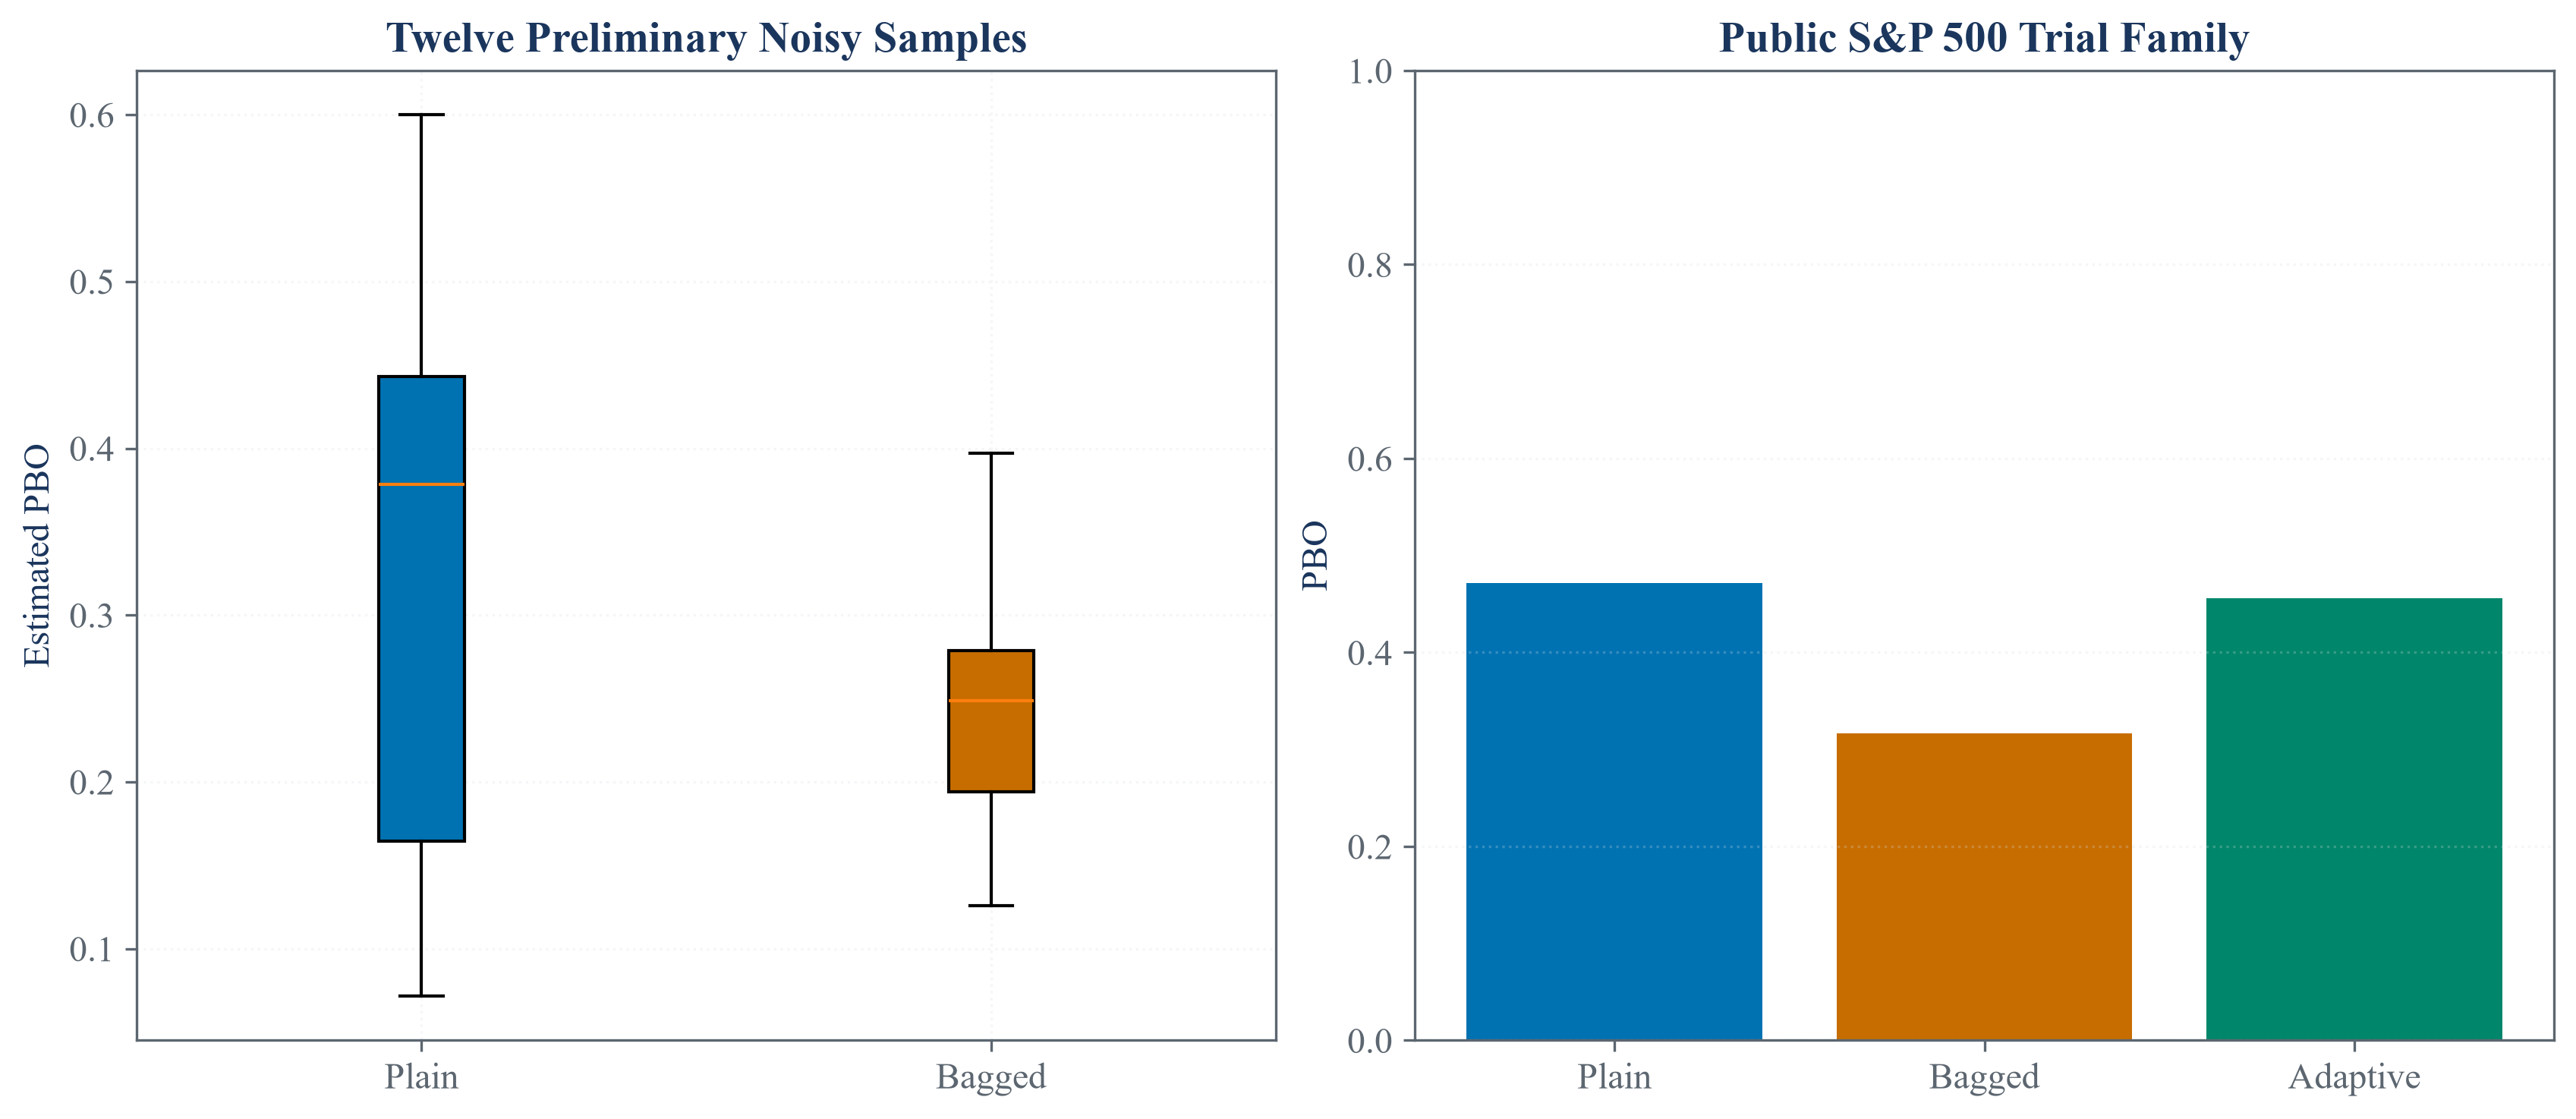

In [4]:
def noisy_performance(seed, n_observations=240, n_trials=8):
    rng = np.random.default_rng(seed)
    return rng.standard_normal((n_observations, n_trials)) * 0.05 + np.linspace(0, 0.004, n_trials)

plain_values = []
bagged_values = []
for seed in range(12):
    matrix = noisy_performance(seed)
    plain_values.append(probability_of_backtest_overfitting(matrix, n_partitions=8, n_jobs=1)[0])
    bagged_values.append(bagged_probability_of_backtest_overfitting(matrix, n_partitions=8, n_bag=25, seed=0)[0])
plain_values = np.asarray(plain_values)
bagged_values = np.asarray(bagged_values)
adaptive_preliminary_pbo, adaptive_preliminary_trial = adaptive_probability_of_backtest_overfitting(noisy_performance(3), n_partitions=8)
preliminary_variant_reproduction = pd.DataFrame({
    "Quantity": ["Plain mean", "Plain spread", "Bagged mean", "Bagged spread", "Adaptive PBO for seed 3", "Adaptive selected index for seed 3"],
    "Value": [plain_values.mean(), plain_values.std(), bagged_values.mean(), bagged_values.std(), adaptive_preliminary_pbo, adaptive_preliminary_trial],
})

public_plain, public_plain_logits = probability_of_backtest_overfitting(performances.to_numpy(), n_partitions=8, n_jobs=1)
public_bagged, public_bag_values = bagged_probability_of_backtest_overfitting(performances.to_numpy(), n_partitions=8, n_bag=40, seed=17)
public_adaptive, public_adaptive_trial = adaptive_probability_of_backtest_overfitting(performances.to_numpy(), n_partitions=8)
public_variants = pd.DataFrame({
    "Calculation": ["Plain", "Bagged", "Adaptive"],
    "PBO": [public_plain, public_bagged, public_adaptive],
    "Repeated estimates": [1, len(public_bag_values), 1],
    "Selected trial": ["Not applicable", "Not applicable", str(public_adaptive_trial + 1)],
})
save_table(preliminary_variant_reproduction, "preliminary_variant_reproduction", "Reproduction of the preliminary plain, bagged, and adaptive calculation.", "tab:chapter17-variant-reproduction", fit=False)
save_table(public_variants, "public_variant_comparison", "Plain, bagged, and adaptive PBO on the public trials.", "tab:chapter17-public-variants", fit=False)
display(preliminary_variant_reproduction)
display(public_variants)

figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.8), constrained_layout=True)
box = axes[0].boxplot([plain_values, bagged_values], tick_labels=["Plain", "Bagged"], patch_artist=True)
box["boxes"][0].set_facecolor(palette["cyan"])
box["boxes"][1].set_facecolor(palette["amber"])
axes[0].set_title("Twelve Preliminary Noisy Samples")
axes[0].set_ylabel("Estimated PBO")
axes[0].grid(alpha=0.25)
axes[1].bar(public_variants["Calculation"], public_variants["PBO"], color=[palette["cyan"], palette["amber"], palette["green"]])
axes[1].set_ylim(0, 1)
axes[1].set_title("Public S&P 500 Trial Family")
axes[1].set_ylabel("PBO")
axes[1].grid(axis="y", alpha=0.25)
figure.savefig(FIGURES / "bagged_adaptive_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "bagged_adaptive_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "bagged_adaptive_comparison.png")))
plt.close(figure)

## Calculation Growth

,Time groups,Logits,PBO,Median seconds,Smallest seconds,Largest seconds,Seconds per logit
0,4,6,1,0.000259,0.000253,0.000282,0.000043
1,6,20,0.950000,0.000713,0.000708,0.000722,0.000036
2,8,70,0.942857,0.002394,0.002393,0.002460,0.000034
3,10,252,0.952381,0.008644,0.008640,0.008668,0.000034
4,12,924,0.923160,0.032904,0.032182,0.033125,0.000036


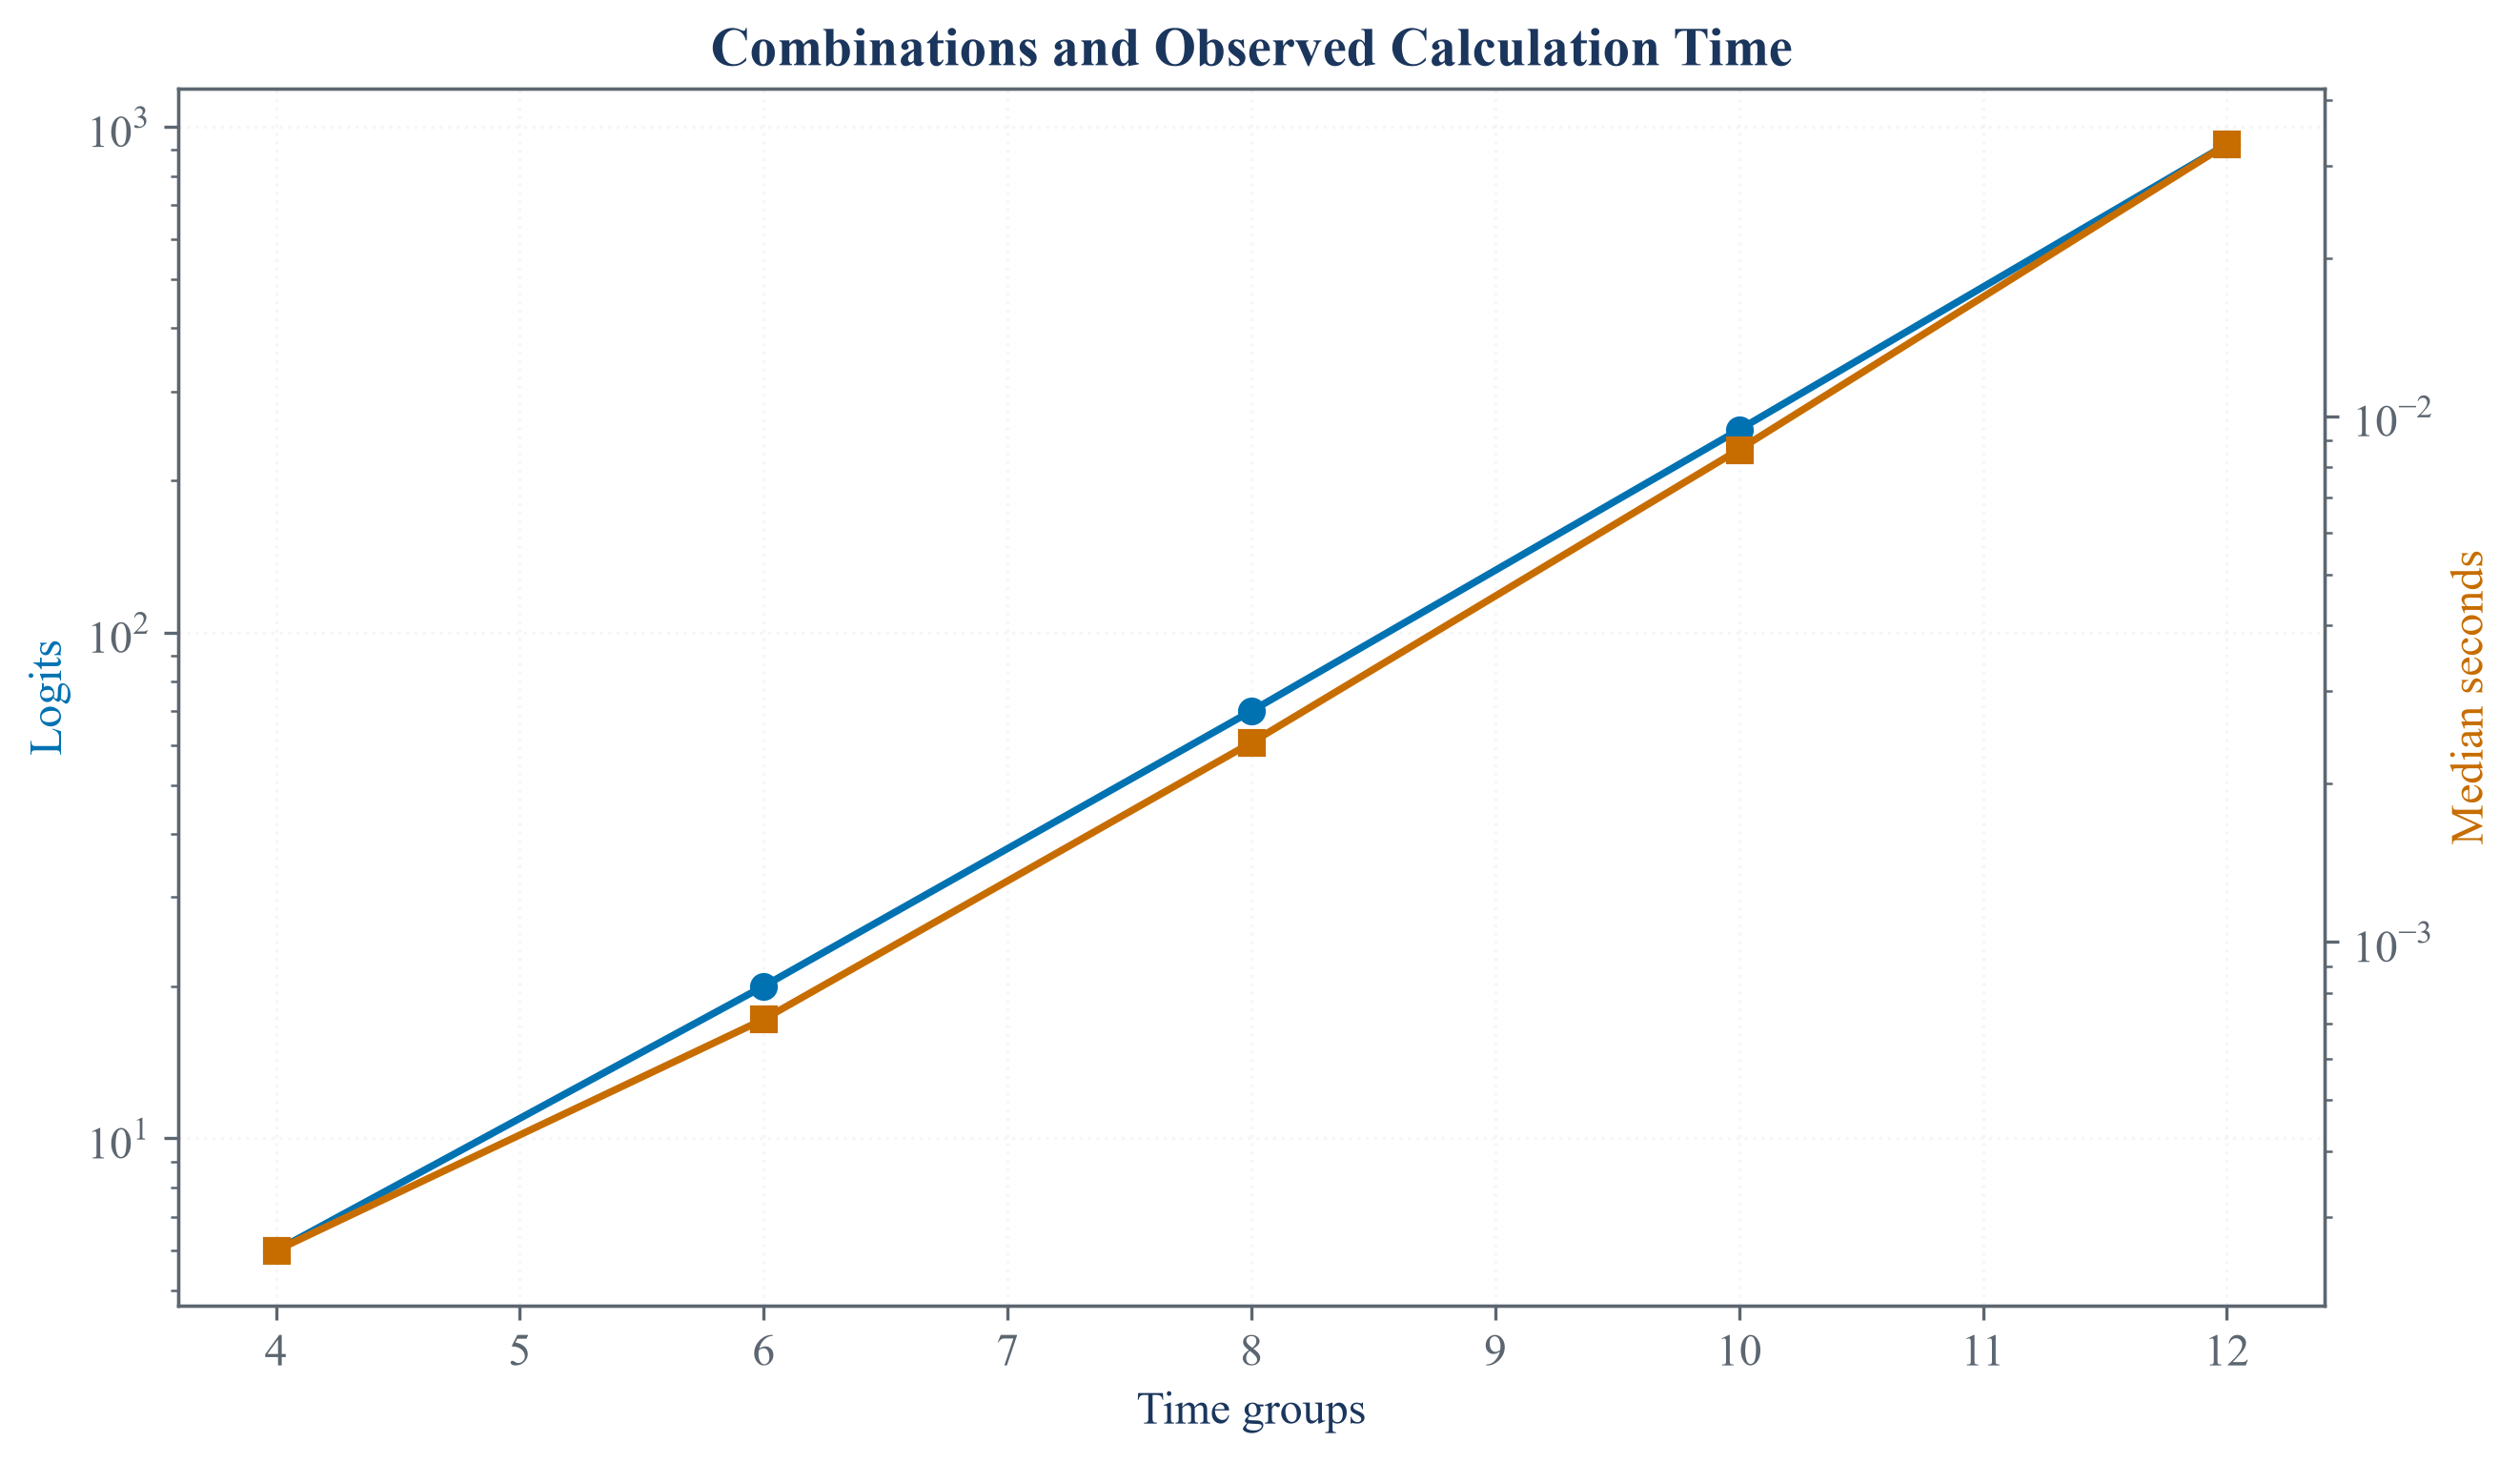

In [5]:
benchmark_matrix = performances.iloc[:480, :16].to_numpy()
probability_of_backtest_overfitting(benchmark_matrix, n_partitions=4, n_jobs=1)
timing_rows = []
for partition_count in [4, 6, 8, 10, 12]:
    elapsed = []
    for repetition in range(3):
        start_time = time.perf_counter()
        value, logits = probability_of_backtest_overfitting(benchmark_matrix, n_partitions=partition_count, n_jobs=1)
        elapsed.append(time.perf_counter() - start_time)
    timing_rows.append({"Time groups": partition_count, "Logits": len(logits), "PBO": value, "Median seconds": float(np.median(elapsed)), "Smallest seconds": float(np.min(elapsed)), "Largest seconds": float(np.max(elapsed))})
calculation_growth = pd.DataFrame(timing_rows)
calculation_growth["Seconds per logit"] = calculation_growth["Median seconds"] / calculation_growth["Logits"]
save_table(calculation_growth, "calculation_growth", "Observed calculation growth for one fixed matrix.", "tab:chapter17-calculation-growth")
display(calculation_growth)

figure, axis_left = plt.subplots(figsize=(8.7, 5.0), constrained_layout=True)
axis_right = axis_left.twinx()
axis_left.plot(calculation_growth["Time groups"], calculation_growth["Logits"], marker="o", color=palette["cyan"], linewidth=1.8, label="Logits")
axis_right.plot(calculation_growth["Time groups"], calculation_growth["Median seconds"], marker="s", color=palette["amber"], linewidth=1.8, label="Median seconds")
axis_left.set_yscale("log")
axis_right.set_yscale("log")
axis_left.set_title("Combinations and Observed Calculation Time")
axis_left.set_xlabel("Time groups")
axis_left.set_ylabel("Logits", color=palette["cyan"])
axis_right.set_ylabel("Median seconds", color=palette["amber"])
axis_left.grid(alpha=0.25)
figure.savefig(FIGURES / "calculation_growth.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "calculation_growth.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "calculation_growth.png")))
plt.close(figure)

## Tests

In [6]:
assert data_hash == EXPECTED_DATA_HASH
assert public_sensitivity.shape == (20, 6)
assert public_sensitivity["PBO"].between(0, 1).all()
assert (public_sensitivity["Logits"] == public_sensitivity["Time groups"].map(lambda value: math.comb(value, value // 2))).all()
assert simulation_results.shape == (480, 5)
assert finite_sample_summary.shape == (12, 6)
assert finite_sample_summary["Mean PBO"].between(0, 1).all()
assert finite_sample_summary["Simulation standard error"].ge(0).all()
assert round(plain_values.mean(), 3) == 0.324
assert round(plain_values.std(), 3) == 0.163
assert round(bagged_values.mean(), 3) == 0.241
assert round(bagged_values.std(), 3) == 0.074
assert round(adaptive_preliminary_pbo, 3) == 0.462
assert adaptive_preliminary_trial == 6
assert bagged_values.std() < plain_values.std()
assert public_variants["PBO"].between(0, 1).all()
assert len(public_bag_values) == 40
assert calculation_growth["Logits"].tolist() == [6, 20, 70, 252, 924]
assert calculation_growth["Median seconds"].gt(0).all()
assert public_variants["Selected trial"].tolist() == ["Not applicable", "Not applicable", str(public_adaptive_trial + 1)]
assert (FIGURES / "public_pbo_sensitivity.pdf").is_file()
assert (FIGURES / "finite_sample_behavior.pdf").is_file()
assert (FIGURES / "bagged_adaptive_comparison.pdf").is_file()
assert (FIGURES / "calculation_growth.pdf").is_file()
assert (TABLES / "public_sensitivity.tex").is_file()
assert (TABLES / "simulation_design.tex").is_file()
assert (TABLES / "finite_sample_summary.tex").is_file()
assert (TABLES / "preliminary_variant_reproduction.tex").is_file()
assert (TABLES / "public_variant_comparison.tex").is_file()
assert (TABLES / "calculation_growth.tex").is_file()